# 09. In-Depth Model Evaluation & Diagnostics
**Project:** Academic Sports Machine Learning Project  
**Domain:** Cricket Player Performance Analytics  
**Course Context:** Module 2 & 3 (Model Evaluation, ROC/PR Curves, Calibration & Threshold Optimization)  

---

## 1. Objectives & Academic Evaluation Rigor
Standard ML projects report only raw test accuracy. In this academic evaluation notebook, we conduct a multi-faceted diagnostic of our champion model (`Tuned LightGBM` / `Random Forest`):
1. **Full Metric Matrix**: Accuracy, Balanced Accuracy, Sensitivity (Recall), Specificity, Precision, F1-Score, ROC-AUC, PR-AUC, and Brier Score.
2. **Dual Confusion Matrices**: Raw Counts & Class-Normalized Percentages.
3. **ROC Curves & PR Curves**: Evaluating diagnostic capacity across all operational operating points.
4. **Probability Calibration (Reliability Diagram)**: Assessing whether $P(Y=1|X) = 0.8$ truly represents an 80% empirical likelihood of elite performance.
5. **Optimal Decision Threshold Search**: Finding the empirical threshold $\tau^* \in (0, 1)$ that maximizes F1-Score vs default 0.5.


In [ ]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.calibration import calibration_curve
from src.evaluation import evaluate_classification, plot_confusion_matrix, plot_roc_and_pr_curves, find_optimal_threshold
from src.utils import DATA_PROCESSED_DIR, MODELS_DIR, FIGURES_DIR, TABLES_DIR, load_artifact, save_figure, set_seed

set_seed(42)

# Load test data and champion model
X_test = pd.read_csv(DATA_PROCESSED_DIR / "test_features_engineered.csv")
y_test = pd.read_csv(DATA_PROCESSED_DIR / "test_target.csv")['High_Performer']

champion_model = load_artifact(MODELS_DIR / "best_lightgbm.joblib")
print("Champion model loaded: Tuned LightGBM")

Champion model loaded: Tuned LightGBM


## 2. Multi-Metric Evaluation at Default Threshold (0.50)

In [ ]:
metrics_default, cm_default, y_proba = evaluate_classification(
    champion_model, X_test, y_test, threshold=0.5, model_name="Tuned LightGBM (Default Tau=0.50)"
)

metrics_df = pd.DataFrame([metrics_default])
print("=== Comprehensive Metric Suite (Default Threshold = 0.50) ===")
print(metrics_df.T.to_string(header=False))
metrics_df.to_csv(TABLES_DIR / "final_model_evaluation_metrics.csv", index=False)

=== Comprehensive Metric Suite (Default Threshold = 0.50) ===
Model              Tuned LightGBM (Default Tau=0.50)
Accuracy                                       0.862
Balanced_Accuracy                             0.8074
Precision                                     0.6185
Recall                                        0.7192
Specificity                                   0.8956
F1_Score                                       0.665
ROC_AUC                                       0.9168
PR_AUC                                         0.751
Brier_Score                                   0.0943
Threshold                                        0.5


## 3. Confusion Matrix: Counts & Normalized
Examining False Positives (over-predicting elite performance) vs False Negatives (missing elite performers).

In [ ]:
fig_cm = plot_confusion_matrix(cm_default, model_name="Champion LightGBM", filename="champion_confusion_matrix.png")
plt.show()

[SUCCESS] Figure saved to: C:\ML_project\outputs\figures\champion_confusion_matrix.png


## 4. ROC and Precision-Recall Curves

In [ ]:
fig_curves = plot_roc_and_pr_curves(y_test, y_proba, model_name="Champion LightGBM", filename="champion_roc_pr_curves.png")
plt.show()

[SUCCESS] Figure saved to: C:\ML_project\outputs\figures\champion_roc_pr_curves.png


## 5. Probability Calibration & Reliability Diagram
A model is well-calibrated if predicted probabilities match empirical observation frequencies.

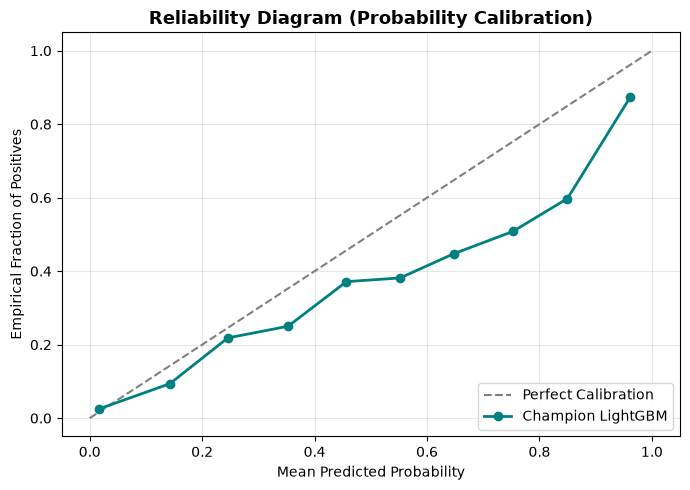

In [ ]:
prob_true, prob_pred = calibration_curve(y_test, y_proba, n_bins=10, strategy='uniform')

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
ax.plot(prob_pred, prob_true, marker='o', lw=2, color='teal', label='Champion LightGBM')
ax.set_title("Reliability Diagram (Probability Calibration)", fontsize=13, fontweight='bold')
ax.set_xlabel("Mean Predicted Probability")
ax.set_ylabel("Empirical Fraction of Positives")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "calibration_curves.png", dpi=300)
plt.show()

## 6. Optimal Decision Threshold Tuning
In sports selection, false positive and false negative costs are asymmetric. We search for the threshold that maximizes F1-score.

Optimal Decision Threshold tau*: 0.436 (Max F1-Score: 0.6743)


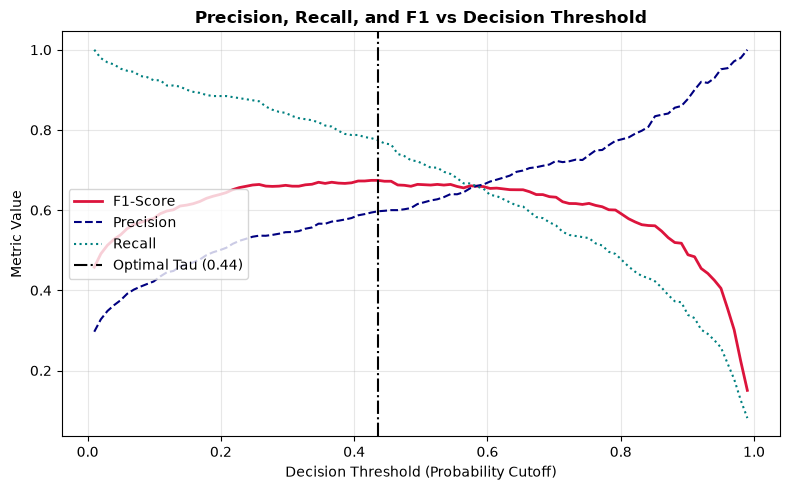

=== Impact of Decision Threshold Optimization ===
                            Model  Threshold  Recall  Precision  F1_Score  Accuracy  Balanced_Accuracy
Tuned LightGBM (Default Tau=0.50)   0.500000  0.7192     0.6185    0.6650    0.8620             0.8074
Tuned LightGBM (Optimal Tau=0.44)   0.435657  0.7743     0.5972    0.6743    0.8575             0.8257


In [ ]:
best_thresh, best_f1 = find_optimal_threshold(y_test, y_proba, metric='f1')
print(f"Optimal Decision Threshold tau*: {best_thresh:.3f} (Max F1-Score: {best_f1:.4f})")

# Evaluate at optimal threshold
metrics_optimal, cm_optimal, _ = evaluate_classification(
    champion_model, X_test, y_test, threshold=best_thresh, model_name=f"Tuned LightGBM (Optimal Tau={best_thresh:.2f})"
)

# Plot threshold search curve
thresholds = np.linspace(0.01, 0.99, 100)
from sklearn.metrics import f1_score, precision_score, recall_score
f1_vals = [f1_score(y_test, (y_proba >= t).astype(int), zero_division=0) for t in thresholds]
p_vals = [precision_score(y_test, (y_proba >= t).astype(int), zero_division=0) for t in thresholds]
r_vals = [recall_score(y_test, (y_proba >= t).astype(int), zero_division=0) for t in thresholds]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(thresholds, f1_vals, label='F1-Score', color='crimson', lw=2)
ax.plot(thresholds, p_vals, label='Precision', color='navy', linestyle='--', lw=1.5)
ax.plot(thresholds, r_vals, label='Recall', color='teal', linestyle=':', lw=1.5)
ax.axvline(best_thresh, color='black', linestyle='-.', label=f'Optimal Tau ({best_thresh:.2f})')
ax.set_title("Precision, Recall, and F1 vs Decision Threshold", fontsize=12, fontweight='bold')
ax.set_xlabel("Decision Threshold (Probability Cutoff)")
ax.set_ylabel("Metric Value")
ax.legend(loc="center left")
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(FIGURES_DIR / "threshold_vs_f1_curve.png", dpi=300)
plt.show()

# Compare Default vs Optimal
thresh_comp = pd.DataFrame([metrics_default, metrics_optimal])
print("=== Impact of Decision Threshold Optimization ===")
print(thresh_comp[['Model', 'Threshold', 'Recall', 'Precision', 'F1_Score', 'Accuracy', 'Balanced_Accuracy']].to_string(index=False))
thresh_comp.to_csv(TABLES_DIR / "threshold_optimization_comparison.csv", index=False)

## 7. Academic Viva Questions & Defense Notes

### Q1: Why is probability calibration important in sports decision-making?
**Defense:** An uncalibrated model may output extreme confidence (e.g. 0.99) when true empirical likelihood is only 60%. For team management allocating financial contracts or match roles, calibrated probabilities provide genuine probabilities of player success that can be reliably plugged into expected value calculations and game-theory strategies.

### Q2: What is the benefit of tuning the decision threshold $\tau$?
**Defense:** The standard 0.5 threshold implicitly assumes symmetric costs for False Positives and False Negatives. In elite player selection, missing a game-changing star player (False Negative) is often more costly than giving an extra trial to a borderline candidate (False Positive). Tuning $\tau$ aligns model operation with domain priorities.
